In [ ]:
from google.colab import files
files.upload()   # choose drl_vs_rules.py

Saving drl_vs_rules.py to drl_vs_rules.py


{'drl_vs_rules.py': b'"""Toy cross-layer controller study: tabular Q-learning vs rule-based, hourly simulator.\nWeather/grid data are SYNTHETIC (no NASA POWER / PVGIS access in sandbox)."""\nimport numpy as np, json, sys\nIT_PEAK=5.0; LAES_CAP=10.0; LAES_P=5.0; ETA=np.sqrt(0.60); BACKLOG_CAP=4.0\nALPHA,BETA,GAMMA=0.4,0.4,2.0   # Eq.10 weights; thermal weight raised from 0.2 to 2.0 so the SLA acts as a near-hard constraint\nT_THR=62.0\n\ndef make_year(rng, pv_mw):\n    d=np.arange(365)[:,None]; h=np.arange(24)[None,:]\n    Tm=25.4+9*np.sin(2*np.pi*(d-105)/365)\n    T=Tm+6*np.sin(2*np.pi*(h-9)/24)+rng.normal(0,1.5,(365,1))\n    T=T+0.0\n    cloud=np.clip(0.80-0.30*np.exp(-((d-215)/35.0)**2)+rng.normal(0,0.18,(365,1)),0.25,1.0)\n    sun=np.clip(np.sin(np.pi*(h-6)/12),0,None)\n    pv=pv_mw*0.78*cloud*sun/0.78*0.78  # peak fraction ~0.78*cloud\n    prof=np.where((h>=8)&(h<20),0.9,0.5)*np.ones((365,1))\n    ci=np.where((h>=10)&(h<16),0.60,np.where((h>=18)&(h<23),0.82,0.72))*np.ones((365,1))\

In [ ]:
!python drl_vs_rules.py 4

In [ ]:
!python drl_vs_rules.py 10

In [ ]:
import json
for pv in (4, 10):
    r = json.load(open(f'results_pv{pv}.json'))
    print(f"\nPV {pv} MW")
    for m in ('em', 'cost', 'pue', 'viol', 'curt', 'ren', 'R'):
        print(f"{m:6s}", "  ".join(f"{k}: {r[k][m][0]:11.3f}" for k in r))


PV 4 MW
em     rule:   21205.763  rl:   21455.257  static:   21775.410
cost   rule: 2921428.816  rl: 2935844.697  static: 3000167.545
pue    rule:       1.188  rl:       1.187  static:       1.201
viol   rule:       0.000  rl:       0.800  static:       0.000
curt   rule:       0.000  rl:       0.000  static:       0.000
ren    rule:       0.175  rl:       0.175  static:       0.173
R      rule:   -6205.200  rl:   -5934.182  static:   -5951.572

PV 10 MW
em     rule:   15761.781  rl:   16037.839  static:   16320.162
cost   rule: 2075439.449  rl: 2092770.007  static: 2146883.489
pue    rule:       1.188  rl:       1.188  static:       1.201
viol   rule:       0.000  rl:       2.800  static:       0.000
curt   rule:     290.256  rl:    1099.836  static:    1029.356
ren    rule:       0.421  rl:       0.407  static:       0.405
R      rule:   -5769.681  rl:   -5477.533  static:   -5515.152


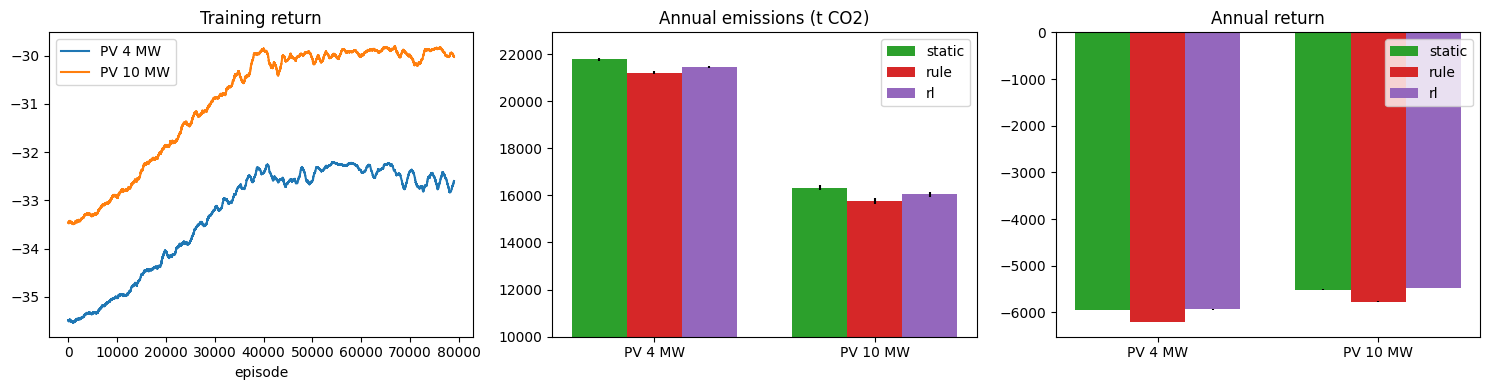

In [ ]:
import numpy as np, matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for pv, c in ((4, 'C0'), (10, 'C1')):
    ret = np.load(f'learning_curve_pv{pv}.npy'); k = 1000
    ax[0].plot(np.convolve(ret, np.ones(k)/k, 'valid'), c, label=f'PV {pv} MW')
ax[0].set_title('Training return'); ax[0].set_xlabel('episode'); ax[0].legend()
for i, (m, t) in enumerate((('em', 'Annual emissions (t CO2)'), ('R', 'Annual return'))):
    for j, k in enumerate(('static', 'rule', 'rl')):
        for p, pv in enumerate((4, 10)):
            r = json.load(open(f'results_pv{pv}.json'))
            ax[i+1].bar(p + (j-1)*.25, r[k][m][0], .25, yerr=r[k][m][1],
                        color=f'C{j+2}', label=k if p == 0 else None)
    ax[i+1].set_xticks([0, 1]); ax[i+1].set_xticklabels(['PV 4 MW', 'PV 10 MW'])
    ax[i+1].set_title(t); ax[i+1].legend()
    if m == 'em': ax[i+1].set_ylim(10000, None)
plt.tight_layout(); plt.show()

In [ ]:
files.download('results_pv4.json')
files.download('results_pv10.json')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

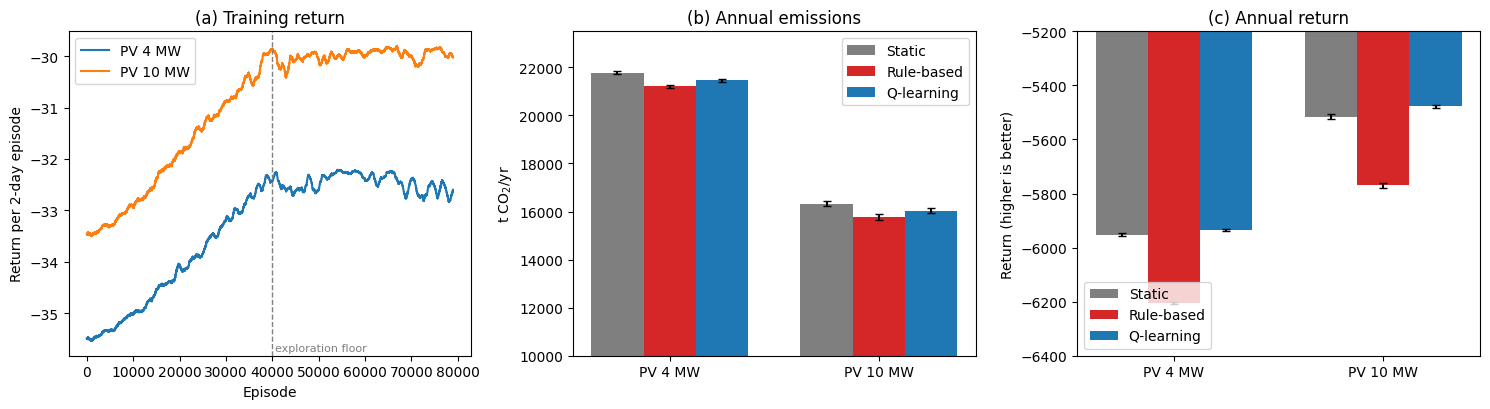

In [ ]:
import json, numpy as np, matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for pv, c in ((4, 'C0'), (10, 'C1')):
    ret = np.load(f'learning_curve_pv{pv}.npy'); k = 1000
    ax[0].plot(np.convolve(ret, np.ones(k)/k, 'valid'), c, label=f'PV {pv} MW')
ax[0].axvline(40000, ls='--', c='gray', lw=1)
ax[0].text(40500, ax[0].get_ylim()[0]+0.1, 'exploration floor', fontsize=8, color='gray')
ax[0].set_title('(a) Training return'); ax[0].set_xlabel('Episode')
ax[0].set_ylabel('Return per 2-day episode'); ax[0].legend(loc='upper left')
names = {'static': 'Static', 'rule': 'Rule-based', 'rl': 'Q-learning'}
cols = {'static': 'C7', 'rule': 'C3', 'rl': 'C0'}
for i, (m, t, yl) in enumerate((('em', '(b) Annual emissions', 't CO$_2$/yr'),
                                ('R', '(c) Annual return', 'Return (higher is better)'))):
    for j, k in enumerate(('static', 'rule', 'rl')):
        for p, pv in enumerate((4, 10)):
            r = json.load(open(f'results_pv{pv}.json'))
            ax[i+1].bar(p + (j-1)*.25, r[k][m][0], .25, yerr=r[k][m][1], capsize=3,
                        color=cols[k], label=names[k] if p == 0 else None)
    ax[i+1].set_xticks([0, 1]); ax[i+1].set_xticklabels(['PV 4 MW', 'PV 10 MW'])
    ax[i+1].set_title(t); ax[i+1].set_ylabel(yl)
    if m == 'em':
        ax[i+1].set_ylim(10000, 23500); ax[i+1].legend(loc='upper right')
    else:
        ax[i+1].set_ylim(-6400, -5200); ax[i+1].legend(loc='lower left')
plt.tight_layout(); plt.savefig('comparison.png', dpi=300); plt.show()

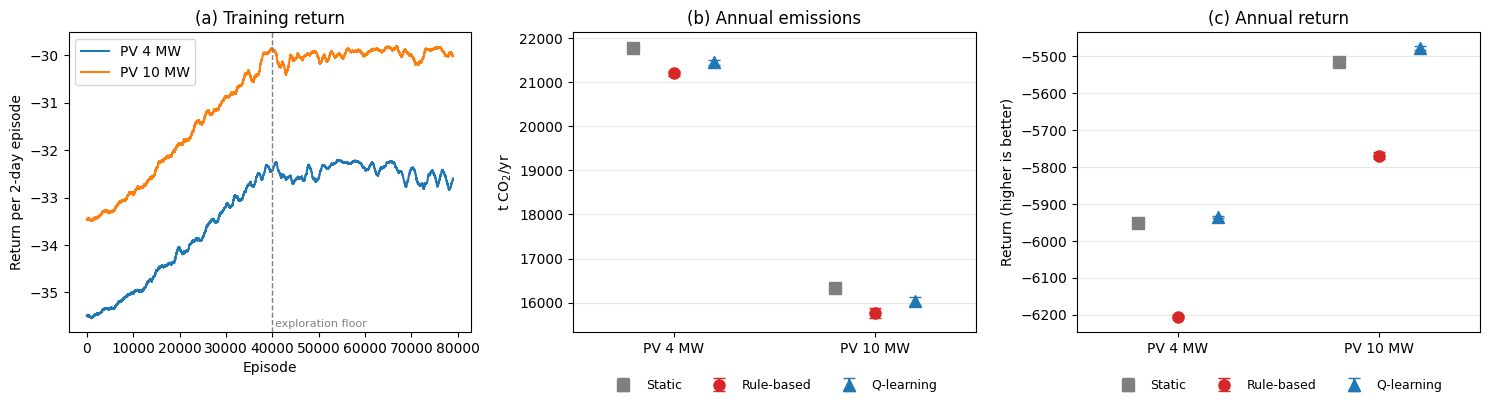

In [ ]:
import json, numpy as np, matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for pv, c in ((4, 'C0'), (10, 'C1')):
    ret = np.load(f'learning_curve_pv{pv}.npy'); k = 1000
    ax[0].plot(np.convolve(ret, np.ones(k)/k, 'valid'), c, label=f'PV {pv} MW')
ax[0].axvline(40000, ls='--', c='gray', lw=1)
ax[0].text(40500, ax[0].get_ylim()[0]+0.1, 'exploration floor', fontsize=8, color='gray')
ax[0].set_title('(a) Training return'); ax[0].set_xlabel('Episode')
ax[0].set_ylabel('Return per 2-day episode'); ax[0].legend(loc='upper left')

names = {'static': 'Static', 'rule': 'Rule-based', 'rl': 'Q-learning'}
cols  = {'static': 'C7', 'rule': 'C3', 'rl': 'C0'}
marks = {'static': 's', 'rule': 'o', 'rl': '^'}
for i, (m, t, yl) in enumerate((('em', '(b) Annual emissions', 't CO$_2$/yr'),
                                ('R', '(c) Annual return', 'Return (higher is better)'))):
    for j, k in enumerate(('static', 'rule', 'rl')):
        for p, pv in enumerate((4, 10)):
            r = json.load(open(f'results_pv{pv}.json'))
            ax[i+1].errorbar(p + (j-1)*.2, r[k][m][0], yerr=r[k][m][1], fmt=marks[k],
                             color=cols[k], capsize=4, ms=8, label=names[k] if p == 0 else None)
    ax[i+1].set_xticks([0, 1]); ax[i+1].set_xticklabels(['PV 4 MW', 'PV 10 MW'])
    ax[i+1].set_xlim(-0.5, 1.5); ax[i+1].grid(axis='y', alpha=0.3)
    ax[i+1].set_title(t); ax[i+1].set_ylabel(yl)
    ax[i+1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=9, frameon=False)
plt.tight_layout(); plt.savefig('comparison.png', dpi=300, bbox_inches='tight'); plt.show()